# Backpropagation Algorithm
<i>Wardatul Keskin |301294696</i>

In [2]:
import json
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, MinMaxScaler

## Data Loading

In [4]:
# Loading training and test data
df_train = pd.read_json("training.json")
df_test = pd.read_json("test.json")

## Data Exploration

In [6]:
# Check Data shapes
print("Training shape:", df_train.shape)
print("Testing shape:", df_test.shape)
# Display first few rows
display(df_train.head())
display(df_test.head())
# Check data info
print(df_train.info())
# Check for missing values
print(df_train.isnull().sum())
# Check class distribution
print(df_train['species'].value_counts())
# Simple statistical summary
print(df_train.describe())

Training shape: (141, 5)
Testing shape: (12, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.4,3.9,1.7,0.4,setosa
1,5.9,3.0,5.1,1.8,virginica
2,6.7,3.3,5.7,2.1,virginica
3,5.0,3.6,1.4,0.2,setosa
4,5.7,2.9,4.2,1.3,versicolor


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 141 entries, 0 to 140
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  141 non-null    float64
 1   sepal_width   141 non-null    float64
 2   petal_length  141 non-null    float64
 3   petal_width   141 non-null    float64
 4   species       141 non-null    object 
dtypes: float64(4), object(1)
memory usage: 5.6+ KB
None
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64
species
setosa        47
versicolor    47
virginica     47
Name: count, dtype: int64
       sepal_length  sepal_width  petal_length  petal_width
count    141.000000   141.000000    141.000000   141.000000
mean       5.837589     3.039007      3.759574     1.196454
std        0.839774     0.435853      1.774340     0.764331
min        4.300000     2.000000      1.000000     0.100000
25%        5.100000     2.800000      1.600000    

<Figure size 700x500 with 0 Axes>

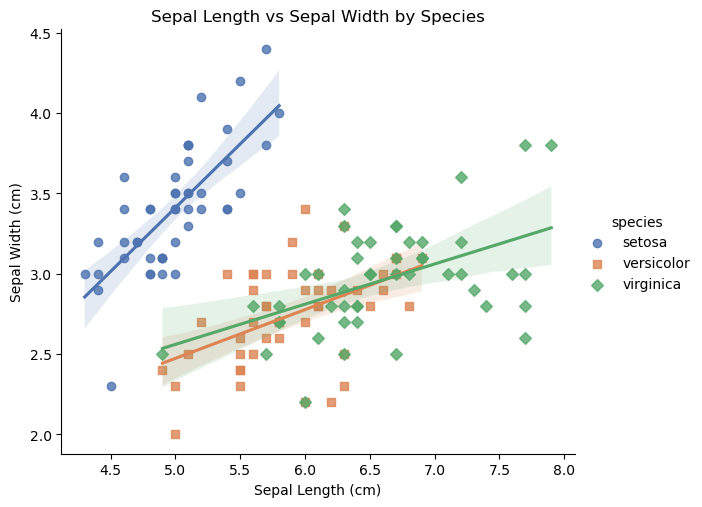

In [7]:
# some visualizations before prepocessing
plt.figure(figsize=(7, 5))
sns.lmplot(
    data=df_train,
    x="sepal_length",
    y="sepal_width",
    hue="species",
    height=5,
    aspect=1.2,
    markers=["o", "s", "D"],
    palette="deep"
)
plt.title("Sepal Length vs Sepal Width by Species", fontsize=12)
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Sepal Width (cm)")
plt.show()

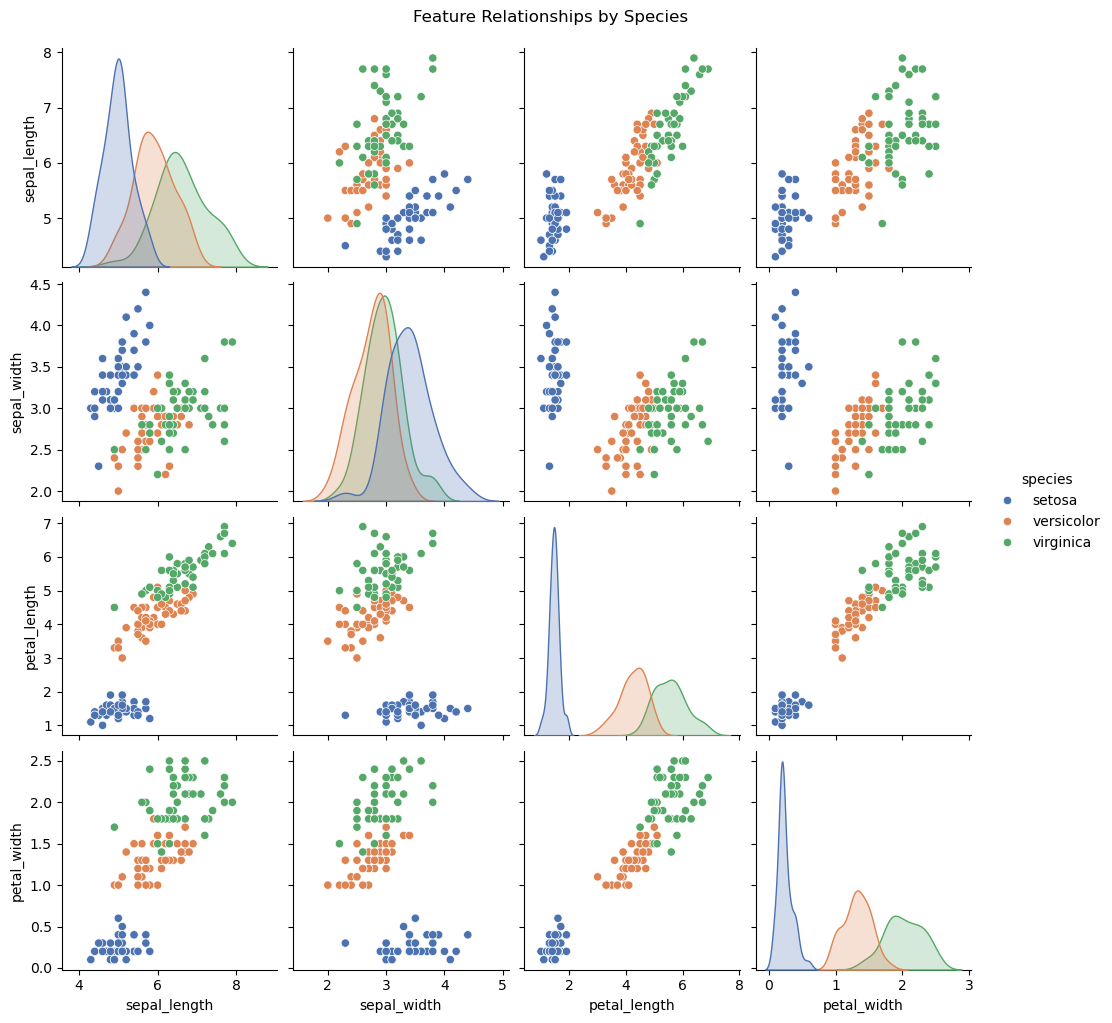

In [8]:
sns.pairplot(df_train, hue="species", diag_kind="kde", palette="deep")
plt.suptitle("Feature Relationships by Species", y=1.02)
plt.show()

In [9]:
# saving the pairplot
plt.savefig("iris_pairplot.png", dpi=300, bbox_inches='tight')

<Figure size 640x480 with 0 Axes>

The pairplot shows that Iris setosa is linearly separable from the other two species based on both petal length and petal width. However, versicolor and virginica overlap in their feature space, suggesting that non-linear decision boundaries are required for accurate classification.

## Data Preparation and Processing

In [12]:
# Data Labelling and Hot Encoding
# Label encoding
label_encoder = LabelEncoder()
y_train_int = label_encoder.fit_transform(df_train['species'])
y_test_int = label_encoder.transform(df_test['species'])

# One-hot Encoding
onehot_encoder = OneHotEncoder(sparse_output=False)
y_train = onehot_encoder.fit_transform(y_train_int.reshape(-1, 1))
y_test = onehot_encoder.transform(y_test_int.reshape(-1, 1))

print("Label classes:", label_encoder.classes_)
print("Example one-hot labelling for setosa:", y_train[0])

Label classes: ['setosa' 'versicolor' 'virginica']
Example one-hot labelling for setosa: [1. 0. 0.]


In [13]:
# Normalization using min-max scaler
# Select numeric features only, dropping the species
X_train = df_train.drop(columns=['species'])
X_test = df_test.drop(columns=['species'])

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Min:", X_train_scaled.min(), "Max:", X_train_scaled.max())
print("X_train:", X_train_scaled.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test_scaled.shape)
print("y_test:", y_test.shape)

Min: 0.0 Max: 1.0
X_train: (141, 4)
y_train: (141, 3)
X_test: (12, 4)
y_test: (12, 3)


## Multi Layer ANN Architecture
<br>There're 4 input features (sepal_length, sepal_width, petal_length, petal_width)<br>
4 (inputs) -- 5 (1 hidden 5 neurons) -- 3(outputs)

In [15]:
# Set hyperparameter
def set_hyperparameters():
    return {
        "epochs": 2000,
        "lr": 0.1,
        "seed": 42
    }

In [16]:
# Initialize weights and biases
def initialize_weights(input_size=14, h1=5, output_size=3, seed=42):
    np.random.seed(seed)
    W1 = np.random.randn(h1, input_size) * 0.01
    b1 = np.zeros((h1, 1))
    W2 = np.random.randn(output_size, h1) * 0.01
    b2 = np.zeros((output_size, 1))
    return {"W1": W1, "b1": b1, "W2": W2, "b2": b2}

In [17]:
# Activation Functions: Sigmoid function and derivative
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def sigmoid_derivative(a):
    return a * (1 - a)

def softmax(z):
    exp_z = np.exp(z - np.max(z, axis=0, keepdims=True))
    return exp_z / np.sum(exp_z, axis=0, keepdims=True)

In [18]:
# Forward propagation
def forward_propagation(X, params):
    W1, b1 = params["W1"], params["b1"]
    W2, b2 = params["W2"], params["b2"]

    Z1 = np.dot(W1, X) + b1
    A1 = sigmoid(Z1)
    Z2 = np.dot(W2, A1) + b2
    A2 = softmax(Z2)  # probabilities for 3 output classes

    cache = {"Z1": Z1, "A1": A1, "Z2": Z2, "A2": A2}
    return A2, cache

In [19]:
# Compute Loss Function
def compute_loss_cross_entropy(A2, Y):
    m = Y.shape[0]
    eps = 1e-15  # avoid log(0)
    loss = -np.sum(Y.T * np.log(A2 + eps)) / m
    return loss

In [20]:
# Backward Propagation
def backward_propagation(X, Y, params, cache):
    m = X.shape[1]  # number of training samples
    # Retrieve parameters
    W1, W2 = params["W1"], params["W2"]
    A1, A2 = cache["A1"], cache["A2"]

    # Output layer of gradient
    # Derivatives using softmax and cross-entropy
    dZ2 = A2 - Y.T
    # Compute gradients for W2 and b2
    dW2 = (1 / m) * np.dot(dZ2, A1.T)                   # weight gradient for output layer
    db2 = (1 / m) * np.sum(dZ2, axis=1, keepdims=True)  # bias gradient for output layer

    # Hidden layer gradient
    # Propagate the error back to hidden layer
    dA1 = np.dot(W2.T, dZ2)
    dZ1 = dA1 * sigmoid_derivative(A1)
    # Compute gradients for W1 and b1
    dW1 = (1 / m) * np.dot(dZ1, X.T)                    # weight gradient for hidden layer
    db1 = (1 / m) * np.sum(dZ1, axis=1, keepdims=True)  # bias gradient for hidden layer

    # Store gradients in dictionary
    grads = {
        "dW1": dW1, "db1": db1,
        "dW2": dW2, "db2": db2
    }
    return grads

In [21]:
# Update weights and biases using gradient descent
def update_weights(params, grads, lr):
    # Hidden layer update
    params["W1"] -= lr * grads["dW1"]
    params["b1"] -= lr * grads["db1"]

    # Output layer update
    params["W2"] -= lr * grads["dW2"]
    params["b2"] -= lr * grads["db2"]
    return params

## Train the model

In [23]:
def train_model(X, Y, hyperparams):
    # 1️Initialize weights
    params = initialize_weights(input_size=4, h1=5, output_size=3, seed=hyperparams["seed"])

    # Initial forward pass (just for inspection)
    A2_init, cache_init = forward_propagation(X, params)
    print("\n=== Initial Activations (first 5 samples) ===")
    print("Hidden Layer (A1):")
    print(cache_init["A1"][:, :5])
    print("\nOutput Layer (A2 - softmax probabilities):")
    print(cache_init["A2"][:, :5])

    losses = []

    # Training loop
    for i in range(hyperparams["epochs"]):
        # Forward pass
        A2, cache = forward_propagation(X, params)

        # Compute cross-entropy loss
        loss = compute_loss_cross_entropy(A2, Y)
        losses.append(loss)

        # Backward pass
        grads = backward_propagation(X, Y, params, cache)

        # Update weights
        params = update_weights(params, grads, hyperparams["lr"])

        # Print progress every 100 epochs
        if i % 100 == 0:
            print(f"Epoch {i:4d} | Cross-Entropy Loss: {loss:.4f}")

    print("\nTraining complete!")
    return params, losses

In [24]:
# Predict the class labels for X using trained parameter
def predict(X, params):
    A2, cache = forward_propagation(X, params)
    predictions = np.argmax(A2, axis=0)
    return predictions, cache 

## Model Results and Evaluation

In [26]:
# Set hyperparameters
hyperparams = set_hyperparameters()

# Train model
params, losses = train_model(X_train_scaled.T, y_train, hyperparams)


=== Initial Activations (first 5 samples) ===
Hidden Layer (A1):
[[0.50032834 0.50033137 0.50020613 0.50024093 0.50027944]
 [0.49985168 0.50000615 0.49992297 0.50009746 0.49984355]
 [0.50045987 0.50024249 0.50044037 0.50037718 0.50054899]
 [0.49679404 0.4977569  0.49739779 0.49743411 0.49657794]
 [0.49962731 0.49960431 0.49984893 0.49980958 0.49973038]]

Output Layer (A2 - softmax probabilities):
[[0.33290812 0.33290676 0.33290637 0.33290632 0.33290802]
 [0.33141211 0.33141265 0.33141251 0.33141177 0.33141184]
 [0.33567977 0.33568059 0.33568111 0.33568192 0.33568013]]
Epoch    0 | Cross-Entropy Loss: 1.0986
Epoch  100 | Cross-Entropy Loss: 1.0986
Epoch  200 | Cross-Entropy Loss: 1.0984
Epoch  300 | Cross-Entropy Loss: 1.0977
Epoch  400 | Cross-Entropy Loss: 1.0953
Epoch  500 | Cross-Entropy Loss: 1.0865
Epoch  600 | Cross-Entropy Loss: 1.0576
Epoch  700 | Cross-Entropy Loss: 0.9825
Epoch  800 | Cross-Entropy Loss: 0.8480
Epoch  900 | Cross-Entropy Loss: 0.7011
Epoch 1000 | Cross-Entro

In [27]:
# Model evaluation
train_preds, cache_train = predict(X_train_scaled.T, params)
test_preds, _ = predict(X_test_scaled.T, params)

# Convert one-hot encoded labels back to integers
y_train_labels = np.argmax(y_train, axis=1)
y_test_labels = np.argmax(y_test, axis=1)

# Calculate accuracy
train_acc = np.mean(train_preds == y_train_labels) * 100
test_acc = np.mean(test_preds == y_test_labels) * 100

print(f"\nTrain Accuracy: {train_acc:.2f}%")
print(f"Test Accuracy: {test_acc:.2f}%")


Train Accuracy: 96.45%
Test Accuracy: 100.00%


In [28]:
# Final Activations after Training
print("\n=== Activations after training (first 5 samples) ===")
print("Hidden Layer (5 neurons):")
print(cache_train["A1"][:, :5])
print("\nOutput Layer (3 neurons - softmax probabilities):")
print(cache_train["A2"][:, :5])


=== Activations after training (first 5 samples) ===
Hidden Layer (5 neurons):
[[0.49520062 0.49865233 0.49753101 0.49831758 0.49464918]
 [0.09222575 0.12186353 0.09839965 0.11008899 0.08416362]
 [0.80234476 0.77697647 0.80026181 0.78893082 0.81127751]
 [0.73561898 0.71603756 0.73745825 0.72719238 0.74394553]
 [0.83248921 0.80596164 0.82913255 0.81775414 0.84124217]]

Output Layer (3 neurons - softmax probabilities):
[[9.47591670e-01 9.31363803e-01 9.45488784e-01 9.38909096e-01
  9.51849856e-01]
 [5.23058937e-02 6.84589396e-02 5.44014917e-02 6.09519781e-02
  4.80643525e-02]
 [1.02436241e-04 1.77257015e-04 1.09724113e-04 1.38925980e-04
  8.57914959e-05]]


In [29]:
# Predicted vs Actual
print("\n=== Predicted vs Actual (first 10 samples) ===")
for i in range(10):
    pred_probs = np.round(cache_train["A2"][:, i], 4)   # softmax probabilities
    actual_label = y_train[i]                           # one-hot true label
    print(f"Predicted Probabilities: {pred_probs}   |  Actual Label (one-hot): {actual_label}")


=== Predicted vs Actual (first 10 samples) ===
Predicted Probabilities: [9.476e-01 5.230e-02 1.000e-04]   |  Actual Label (one-hot): [1. 0. 0.]
Predicted Probabilities: [9.314e-01 6.850e-02 2.000e-04]   |  Actual Label (one-hot): [1. 0. 0.]
Predicted Probabilities: [9.455e-01 5.440e-02 1.000e-04]   |  Actual Label (one-hot): [1. 0. 0.]
Predicted Probabilities: [9.389e-01 6.100e-02 1.000e-04]   |  Actual Label (one-hot): [1. 0. 0.]
Predicted Probabilities: [9.518e-01 4.810e-02 1.000e-04]   |  Actual Label (one-hot): [1. 0. 0.]
Predicted Probabilities: [9.458e-01 5.400e-02 1.000e-04]   |  Actual Label (one-hot): [1. 0. 0.]
Predicted Probabilities: [9.437e-01 5.620e-02 1.000e-04]   |  Actual Label (one-hot): [1. 0. 0.]
Predicted Probabilities: [9.367e-01 6.320e-02 1.000e-04]   |  Actual Label (one-hot): [1. 0. 0.]
Predicted Probabilities: [9.406e-01 5.930e-02 1.000e-04]   |  Actual Label (one-hot): [1. 0. 0.]
Predicted Probabilities: [9.478e-01 5.210e-02 1.000e-04]   |  Actual Label (one

In [62]:
results_df = pd.DataFrame({
    "Predicted": [label_encoder.classes_[i] for i in test_preds],
    "Actual": [label_encoder.classes_[i] for i in y_test_labels]
})
print("\n=== Test Classification Results ===")
display(results_df.head(10))



=== Test Classification Results ===


,Predicted,Actual
0,setosa,setosa
1,virginica,virginica
2,virginica,virginica
3,setosa,setosa
4,versicolor,versicolor
5,virginica,virginica
6,virginica,virginica
7,virginica,virginica
8,setosa,setosa
9,setosa,setosa


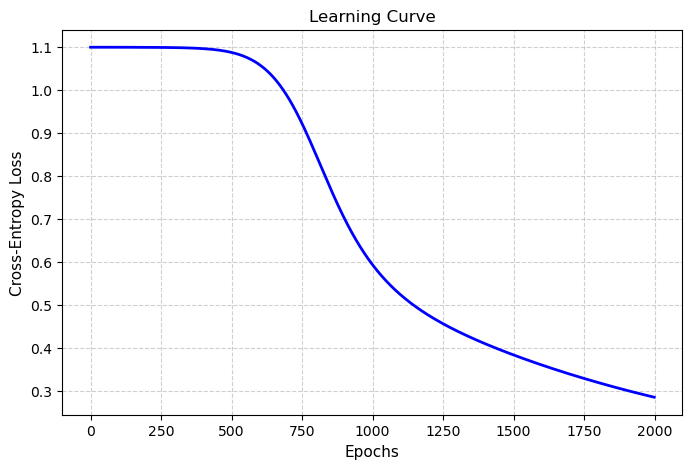

In [31]:
plt.figure(figsize=(8, 5))
plt.plot(losses, color='blue', linewidth=2)
plt.title("Learning Curve", fontsize=12)
plt.xlabel("Epochs", fontsize=11)
plt.ylabel("Cross-Entropy Loss", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()